# Telco Customer Churn Prediction

**Student ID:** 202300329

**Dataset:** [IBM Telco Customer Churn (Kaggle)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

**Task:** binary classification: predict whether a customer churns (Yes/No).

## 1. Load the Data

In [1]:
import pandas as pd

STUDENT_ID = 202300329  

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.info()
df.head()

(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Personalised Subsample

**Method:** stratified 80% subsample of the full dataset using `train_test_split`, with `random_state = 202300329` (my TKH student ID) and `stratify = Churn` so the class balance is kept. All results in this notebook use this subsample (5,634 rows).

In [ ]:


df_p, _ = train_test_split(df, train_size=0.8, stratify=df["Churn"], random_state=STUDENT_ID)
df_p = df_p.reset_index(drop=True)
print(df_p.shape)
print(df_p["Churn"].value_counts(normalize=True))

tc = pd.to_numeric(df_p["TotalCharges"], errors="coerce")
print("Unconvertible TotalCharges:", tc.isna().sum())
df_p[tc.isna()][["tenure", "MonthlyCharges", "TotalCharges"]]

(5634, 21)
Churn
No     0.734647
Yes    0.265353
Name: proportion, dtype: float64
Unconvertible TotalCharges: 9


,tenure,MonthlyCharges,TotalCharges
1592,0,61.90,
1872,0,25.75,
2216,0,19.85,
2300,0,52.55,
2518,0,25.35,
3506,0,20.25,
3877,0,19.70,
3991,0,73.35,
5408,0,80.85,


## 3. Data Cleaning

- **TotalCharges:** the 9 blanks all have `tenure == 0` (new customers not billed yet), so their true value is 0. Imputing 0 is correct; mean/median would invent charges.
- **customerID** is an identifier with no predictive value, so it is dropped.
- **"No internet service" / "No phone service"** are merged into "No", because `InternetService` and `PhoneService` already hold that information.
- **Churn** is converted to 0/1.

In [3]:
df_p = df_p.drop(columns="customerID")
df_p = df_p.replace({"No internet service": "No", "No phone service": "No"})
df_p["TotalCharges"] = pd.to_numeric(df_p["TotalCharges"], errors="coerce").fillna(0.0)
df_p["Churn"] = df_p["Churn"].map({"No": 0, "Yes": 1})

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = df_p.select_dtypes(exclude="number").columns.tolist()

print("Missing values:", df_p.isna().sum().sum())
print("Duplicate rows:", df_p.duplicated().sum())
df_p[df_p.duplicated(keep=False)][["tenure", "Contract", "InternetService", "MonthlyCharges"]].head()

Missing values: 0
Duplicate rows: 17


,tenure,Contract,InternetService,MonthlyCharges
48,1,Month-to-month,Fiber optic,70.10
112,1,Month-to-month,No,20.20
302,1,Month-to-month,No,20.05
360,1,Month-to-month,Fiber optic,70.15
435,1,Month-to-month,Fiber optic,69.20


The duplicated rows are all 1-month, month-to-month customers on basic plans. Different customers can easily share an identical profile, so they are kept as real observations.

## 4. Exploratory Data Analysis

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

df_p[num_cols].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,5634.00,5634.00,5634.00
mean,32.53,65.12,2299.16
std,24.51,30.16,2271.29
min,0.00,18.25,0.00
25%,9.00,35.82,410.21
50%,29.00,70.70,1413.60
75%,55.75,90.10,3835.26
max,72.00,118.75,8684.80


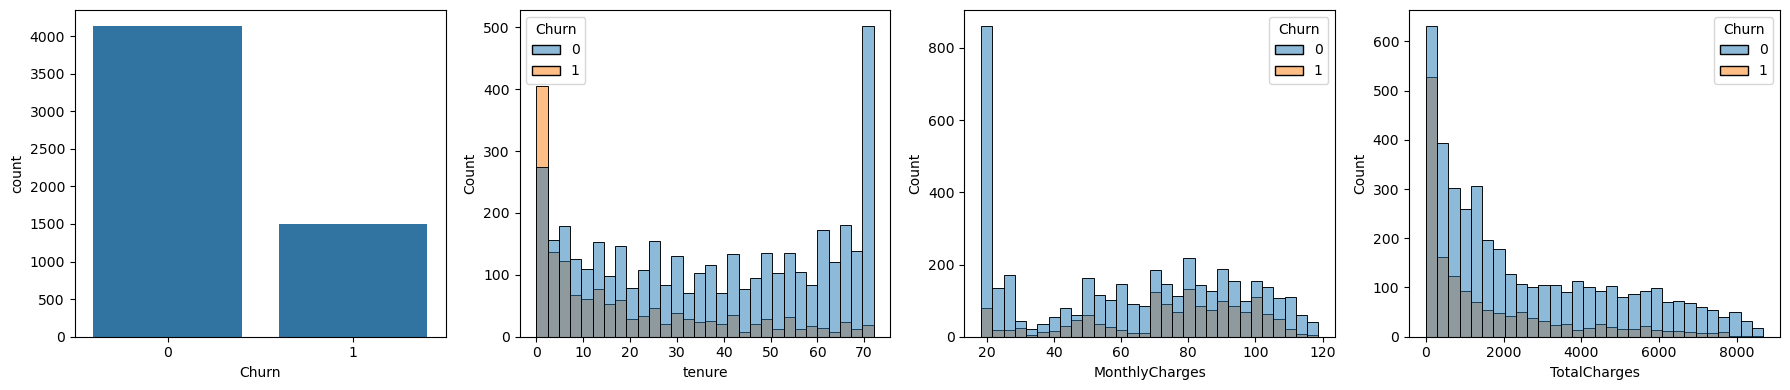

In [ ]:

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
sns.countplot(data=df_p, x="Churn", ax=axes[0])
for ax, c in zip(axes[1:], num_cols):
    sns.histplot(data=df_p, x=c, hue="Churn", bins=30, ax=ax)
plt.tight_layout(); plt.show()

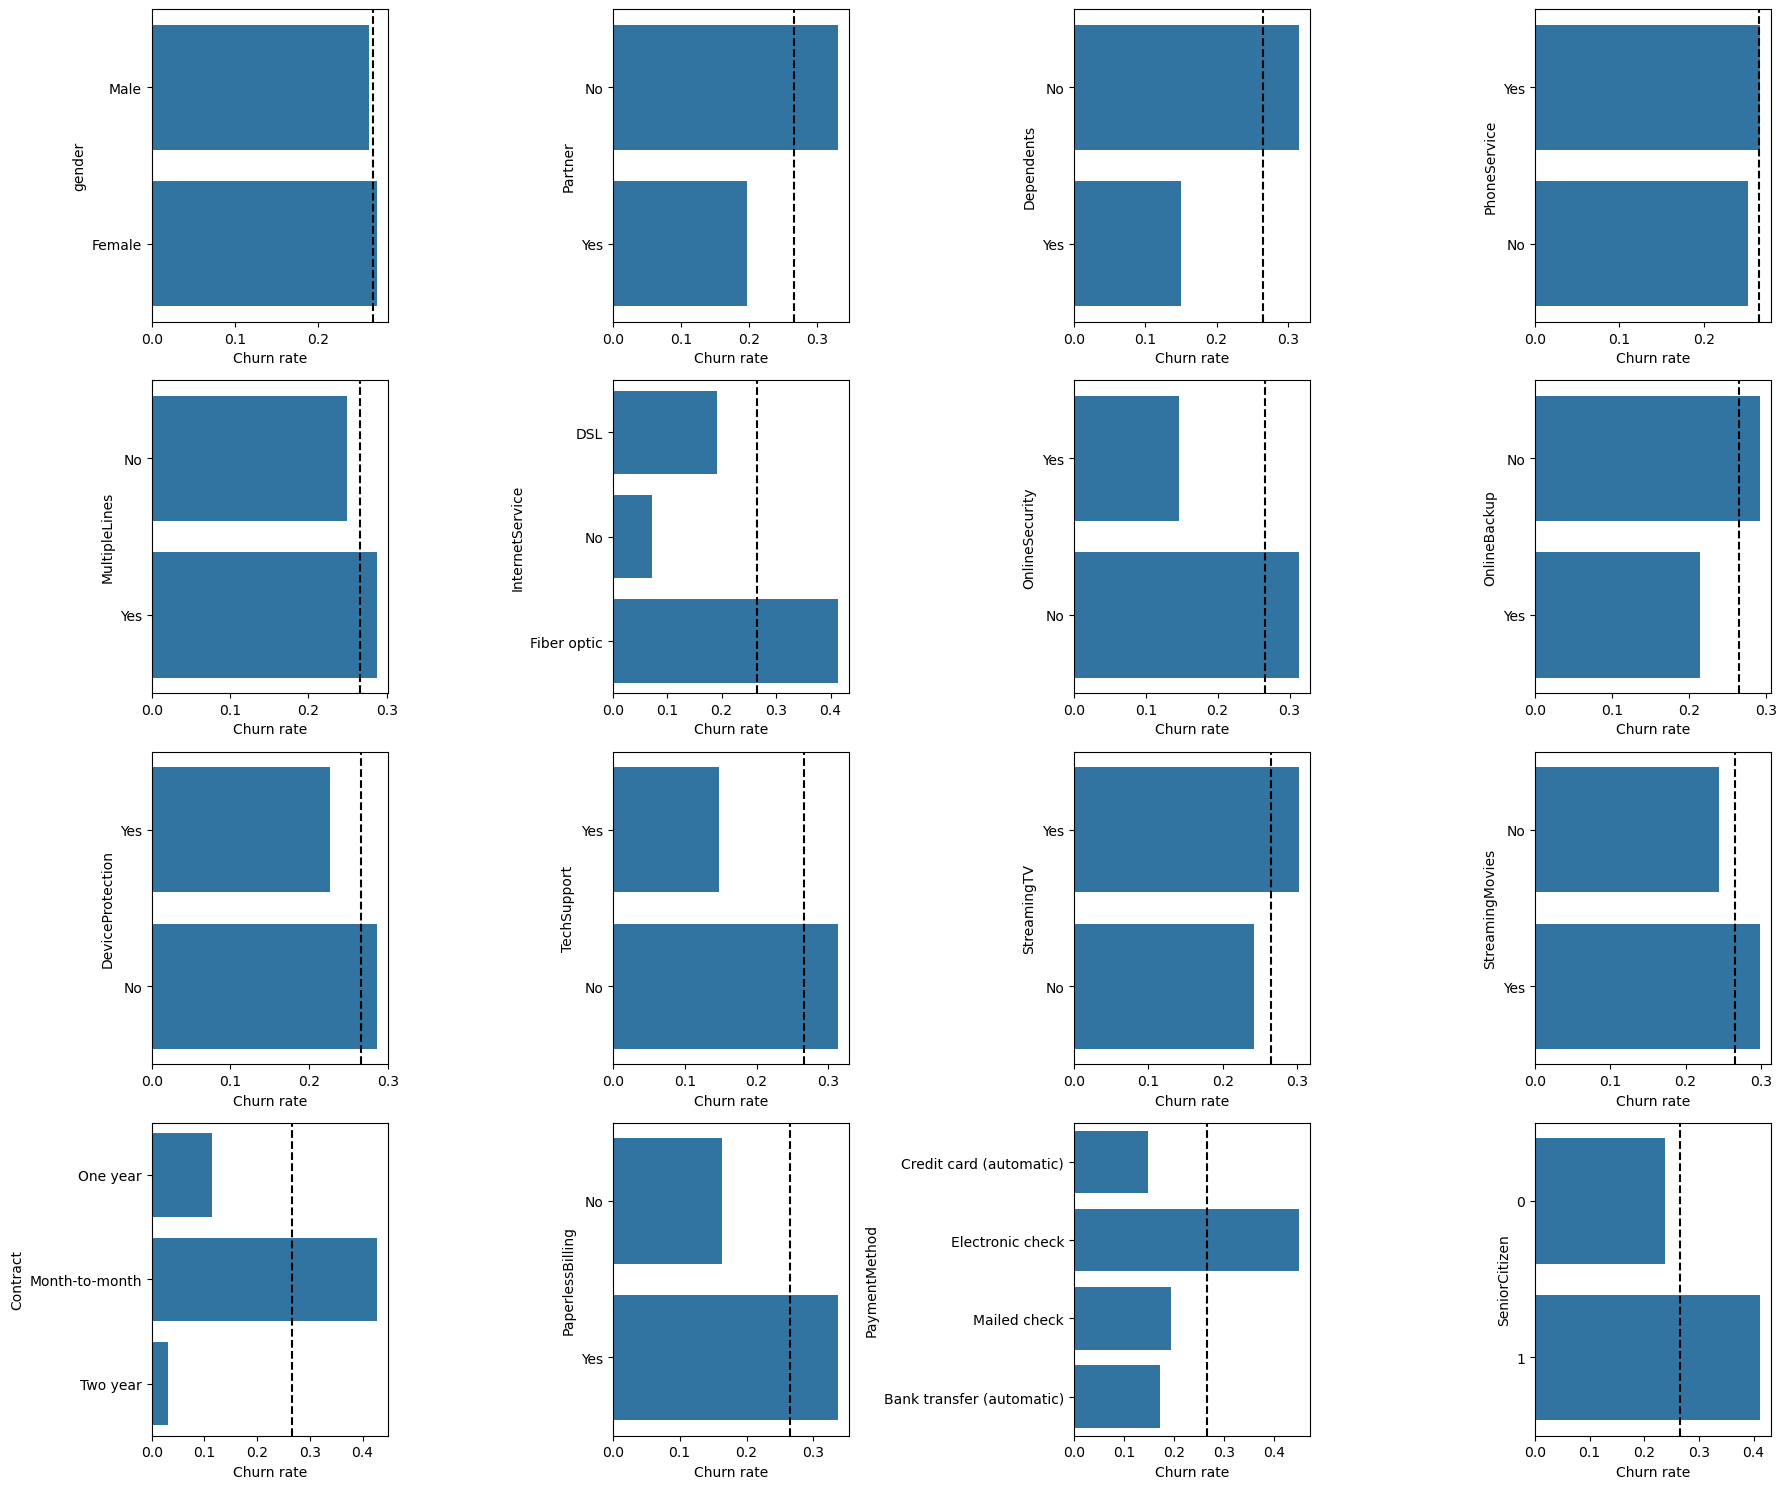

In [ ]:

fig, axes = plt.subplots(4, 4, figsize=(18, 15))
for ax, c in zip(axes.flat, cat_cols + ["SeniorCitizen"]):
    sns.barplot(data=df_p, y=c, x="Churn", errorbar=None, orient="h", ax=ax)
    ax.axvline(df_p["Churn"].mean(), ls="--", color="black")
    ax.set_xlabel("Churn rate")
plt.tight_layout(); plt.show()

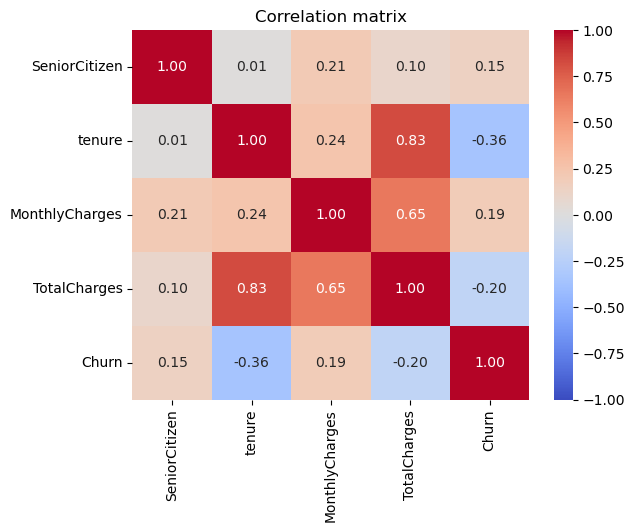

In [7]:
sns.heatmap(df_p.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix"); plt.show()

## 5. Outlier Detection (IQR rule)

Outliers per column:
tenure            0
MonthlyCharges    0
TotalCharges      0
dtype: int64


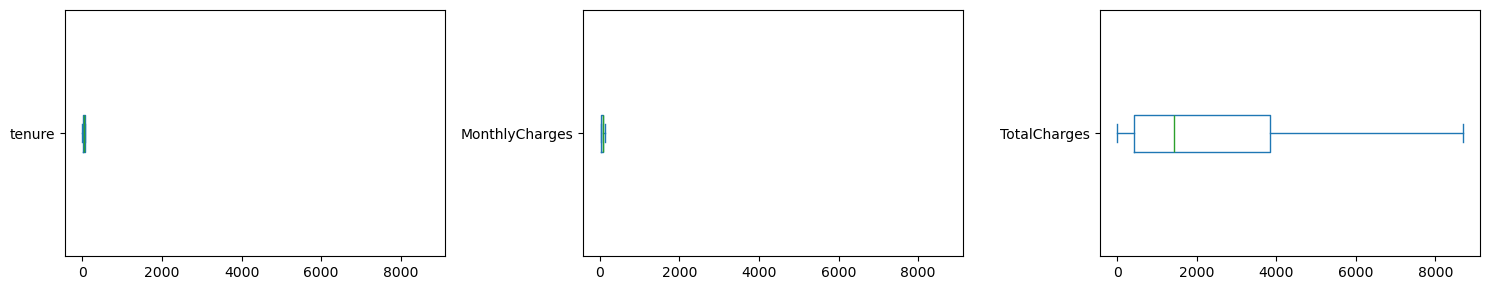

In [8]:
q1, q3 = df_p[num_cols].quantile(0.25), df_p[num_cols].quantile(0.75)
iqr = q3 - q1
print("Outliers per column:")
print(((df_p[num_cols] < q1 - 1.5 * iqr) | (df_p[num_cols] > q3 + 1.5 * iqr)).sum())

df_p[num_cols].plot(kind="box", subplots=True, vert=False, layout=(1, 3), figsize=(15, 3))
plt.tight_layout(); plt.show()

No values fall outside the IQR bounds, so no outlier removal or capping is needed. TotalCharges is right-skewed because of many new customers, but every value is plausible.

## 6. Train/Test Split and Pre-processing Pipeline

The split happens **before** fitting the scaler/encoder, so the test set never influences pre-processing (no leakage). The seed is again my student ID. In Milestone 2 this `preprocessor` goes inside each model's `Pipeline`.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X, y = df_p.drop(columns="Churn"), df_p["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=STUDENT_ID)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
], remainder="passthrough")  # SeniorCitizen is already 0/1

X_train_prep = preprocessor.fit_transform(X_train)   # fit on train only
X_test_prep = preprocessor.transform(X_test)
print("Train:", X_train_prep.shape, " Test:", X_test_prep.shape)
print("Churn rate train/test:", round(y_train.mean(), 4), round(y_test.mean(), 4))
print(list(preprocessor.get_feature_names_out()))

Train: (4507, 26)  Test: (1127, 26)
Churn rate train/test: 0.2654 0.2653
['num__tenure', 'num__MonthlyCharges', 'num__TotalCharges', 'cat__gender_Male', 'cat__Partner_Yes', 'cat__Dependents_Yes', 'cat__PhoneService_Yes', 'cat__MultipleLines_Yes', 'cat__InternetService_DSL', 'cat__InternetService_Fiber optic', 'cat__InternetService_No', 'cat__OnlineSecurity_Yes', 'cat__OnlineBackup_Yes', 'cat__DeviceProtection_Yes', 'cat__TechSupport_Yes', 'cat__StreamingTV_Yes', 'cat__StreamingMovies_Yes', 'cat__Contract_Month-to-month', 'cat__Contract_One year', 'cat__Contract_Two year', 'cat__PaperlessBilling_Yes', 'cat__PaymentMethod_Bank transfer (automatic)', 'cat__PaymentMethod_Credit card (automatic)', 'cat__PaymentMethod_Electronic check', 'cat__PaymentMethod_Mailed check', 'remainder__SeniorCitizen']
